In [1]:
# Research review: Recovered metadata, field-summary and feature-engineering workflow. Execute from the project root with approved data; exported files can overwrite root-level table copies.
import os
import re
import h5py
import numpy as np
import pandas as pd
import xml.etree.ElementTree as ET

In [2]:
ROOT_FOLDER = "RO_data"



In [3]:
all_files=[]

for root,dirs,files in os.walk(ROOT_FOLDER):

    for file in files:

        if file.endswith(".h5"):

            h5_path=os.path.join(root,file)

            xmf_path=os.path.join(root,file.replace(".h5",".xmf"))

            if os.path.exists(xmf_path):

                all_files.append((h5_path,xmf_path))

print("Total paired files :",len(all_files))

Total paired files : 1268


In [4]:
for h5,xmf in all_files[:10]:

    print(h5)

RO_data\configuration1_interspacer0.75mm\HR_spacer_images\100_spacer_image.h5
RO_data\configuration1_interspacer0.75mm\HR_spacer_images\101_spacer_image.h5
RO_data\configuration1_interspacer0.75mm\HR_spacer_images\102_spacer_image.h5
RO_data\configuration1_interspacer0.75mm\HR_spacer_images\103_spacer_image.h5
RO_data\configuration1_interspacer0.75mm\HR_spacer_images\104_spacer_image.h5
RO_data\configuration1_interspacer0.75mm\HR_spacer_images\105_spacer_image.h5
RO_data\configuration1_interspacer0.75mm\HR_spacer_images\106_spacer_image.h5
RO_data\configuration1_interspacer0.75mm\HR_spacer_images\107_spacer_image.h5
RO_data\configuration1_interspacer0.75mm\HR_spacer_images\108_spacer_image.h5
RO_data\configuration1_interspacer0.75mm\HR_spacer_images\109_spacer_image.h5


In [5]:
metadata=[]

for h5_path,xmf_path in all_files:

    folder=os.path.dirname(h5_path)

    config_folder=os.path.basename(os.path.dirname(folder))

    resolution=os.path.basename(folder)

    image=int(re.findall(r'\d+',os.path.basename(h5_path))[0])

    match=re.search(r'configuration(\d+)_interspacer([\d\.]+)mm',config_folder)

    if match:

        config_number=int(match.group(1))

        spacer=float(match.group(2))

    else:

        config_number=None
        spacer=None

    metadata.append({

        "Configuration_Number":config_number,

        "Spacer_mm":spacer,

        "Configuration_Name":config_folder,

        "Resolution":resolution,

        "Image_Number":image,

        "H5_File":h5_path,

        "XMF_File":xmf_path

    })

In [6]:
# Research review: Cell 7 repeats this metadata export. Both original implementations are retained for provenance.
metadata_df=pd.DataFrame(metadata)

metadata_df=metadata_df.sort_values(

    by=[

        "Configuration_Number",

        "Resolution",

        "Image_Number"

    ]

)

metadata_df.to_excel("Metadata.xlsx",index=False)

metadata_df.head(20)

,Configuration_Number,Spacer_mm,Configuration_Name,Resolution,Image_Number,H5_File,XMF_File
110,1,0.75,configuration1_interspacer0.75mm,HR_spacer_images,1,RO_data\configuration1_interspacer0.75mm\HR_sp...,RO_data\configuration1_interspacer0.75mm\HR_sp...
121,1,0.75,configuration1_interspacer0.75mm,HR_spacer_images,2,RO_data\configuration1_interspacer0.75mm\HR_sp...,RO_data\configuration1_interspacer0.75mm\HR_sp...
132,1,0.75,configuration1_interspacer0.75mm,HR_spacer_images,3,RO_data\configuration1_interspacer0.75mm\HR_sp...,RO_data\configuration1_interspacer0.75mm\HR_sp...
143,1,0.75,configuration1_interspacer0.75mm,HR_spacer_images,4,RO_data\configuration1_interspacer0.75mm\HR_sp...,RO_data\configuration1_interspacer0.75mm\HR_sp...
154,1,0.75,configuration1_interspacer0.75mm,HR_spacer_images,5,RO_data\configuration1_interspacer0.75mm\HR_sp...,RO_data\configuration1_interspacer0.75mm\HR_sp...
165,1,0.75,configuration1_interspacer0.75mm,HR_spacer_images,6,RO_data\configuration1_interspacer0.75mm\HR_sp...,RO_data\configuration1_interspacer0.75mm\HR_sp...
176,1,0.75,configuration1_interspacer0.75mm,HR_spacer_images,7,RO_data\configuration1_interspacer0.75mm\HR_sp...,RO_data\configuration1_interspacer0.75mm\HR_sp...
187,1,0.75,configuration1_interspacer0.75mm,HR_spacer_images,8,RO_data\configuration1_interspacer0.75mm\HR_sp...,RO_data\configuration1_interspacer0.75mm\HR_sp...
198,1,0.75,configuration1_interspacer0.75mm,HR_spacer_images,9,RO_data\configuration1_interspacer0.75mm\HR_sp...,RO_data\configuration1_interspacer0.75mm\HR_sp...
10,1,0.75,configuration1_interspacer0.75mm,HR_spacer_images,10,RO_data\configuration1_interspacer0.75mm\HR_sp...,RO_data\configuration1_interspacer0.75mm\HR_sp...


In [7]:
metadata_df=pd.DataFrame(metadata)

metadata_df=metadata_df.sort_values(

    by=[

        "Configuration_Number",

        "Resolution",

        "Image_Number"

    ]

)

metadata_df.to_excel("Metadata.xlsx",index=False)

metadata_df.head(20)

,Configuration_Number,Spacer_mm,Configuration_Name,Resolution,Image_Number,H5_File,XMF_File
110,1,0.75,configuration1_interspacer0.75mm,HR_spacer_images,1,RO_data\configuration1_interspacer0.75mm\HR_sp...,RO_data\configuration1_interspacer0.75mm\HR_sp...
121,1,0.75,configuration1_interspacer0.75mm,HR_spacer_images,2,RO_data\configuration1_interspacer0.75mm\HR_sp...,RO_data\configuration1_interspacer0.75mm\HR_sp...
132,1,0.75,configuration1_interspacer0.75mm,HR_spacer_images,3,RO_data\configuration1_interspacer0.75mm\HR_sp...,RO_data\configuration1_interspacer0.75mm\HR_sp...
143,1,0.75,configuration1_interspacer0.75mm,HR_spacer_images,4,RO_data\configuration1_interspacer0.75mm\HR_sp...,RO_data\configuration1_interspacer0.75mm\HR_sp...
154,1,0.75,configuration1_interspacer0.75mm,HR_spacer_images,5,RO_data\configuration1_interspacer0.75mm\HR_sp...,RO_data\configuration1_interspacer0.75mm\HR_sp...
165,1,0.75,configuration1_interspacer0.75mm,HR_spacer_images,6,RO_data\configuration1_interspacer0.75mm\HR_sp...,RO_data\configuration1_interspacer0.75mm\HR_sp...
176,1,0.75,configuration1_interspacer0.75mm,HR_spacer_images,7,RO_data\configuration1_interspacer0.75mm\HR_sp...,RO_data\configuration1_interspacer0.75mm\HR_sp...
187,1,0.75,configuration1_interspacer0.75mm,HR_spacer_images,8,RO_data\configuration1_interspacer0.75mm\HR_sp...,RO_data\configuration1_interspacer0.75mm\HR_sp...
198,1,0.75,configuration1_interspacer0.75mm,HR_spacer_images,9,RO_data\configuration1_interspacer0.75mm\HR_sp...,RO_data\configuration1_interspacer0.75mm\HR_sp...
10,1,0.75,configuration1_interspacer0.75mm,HR_spacer_images,10,RO_data\configuration1_interspacer0.75mm\HR_sp...,RO_data\configuration1_interspacer0.75mm\HR_sp...


In [10]:
def read_xmf_mapping(xmf_file):

    tree = ET.parse(xmf_file)
    root = tree.getroot()

    mapping = {}

    for attribute in root.iter():

        if "Attribute" in attribute.tag:

            variable = attribute.attrib.get("Name")

            for child in attribute:

                if "DataItem" in child.tag:

                    if child.text is None:
                        continue

                    text = child.text.strip()

                    dataset = text.split(":")[-1].replace("/", "")

                    mapping[variable] = dataset

    return mapping

In [8]:
summary_data = []

raw_data = []

In [18]:
for index,row in metadata_df.iterrows():

    h5_file=row["H5_File"]

    xmf_file=row["XMF_File"]

    print(f"{index+1}/{len(metadata_df)} : {os.path.basename(h5_file)}")

    mapping=read_xmf_mapping(xmf_file)

    with h5py.File(h5_file,"r") as h5:
        C=h5[mapping["C"]][:]

        U=h5[mapping["U"]][:]

        P=h5[mapping["p"]][:]

        PRGH=h5[mapping["p_rgh"]][:]

        RHO=h5[mapping["rho"]][:]

        VISC=h5[mapping["visc"]][:]
    
        Ux=U[:,:,:,0]

        Uy=U[:,:,:,1]

        Uz=U[:,:,:,2]

        Velocity=np.sqrt(Ux**2+Uy**2+Uz**2)
        nx=C.shape[0]

        ny=C.shape[2]

        print("Grid :",nx,"x",ny)
    
        summary_data.append({

            "Configuration_Number":row["Configuration_Number"],

            "Spacer_mm":row["Spacer_mm"],

            "Resolution":row["Resolution"],

            "Image":row["Image_Number"],

            "Grid_X":nx,

            "Grid_Y":ny,

            "Mean_Concentration":C.mean(),

            "Std_Concentration":C.std(),

            "Min_Concentration":C.min(),

            "Max_Concentration":C.max(),

            "Mean_Velocity":Velocity.mean(),

            "Max_Velocity":Velocity.max(),

            "Min_Velocity":Velocity.min(),

            "Std_Velocity":Velocity.std(),

            "Mean_Pressure":P.mean(),

            "Max_Pressure":P.max(),

            "Min_Pressure":P.min(),

            "Std_Pressure":P.std(),

            "Mean_p_rgh":PRGH.mean(),

            "Mean_Density":RHO.mean(),

            "Mean_Viscosity":VISC.mean(),

            "Mean_Ux":Ux.mean(),

            "Mean_Uy":Uy.mean(),

            "Mean_Uz":Uz.mean()

        })

111/1268 : 1_spacer_image.h5
Grid : 100 x 100
122/1268 : 2_spacer_image.h5
Grid : 100 x 100
133/1268 : 3_spacer_image.h5
Grid : 100 x 100
144/1268 : 4_spacer_image.h5
Grid : 100 x 100
155/1268 : 5_spacer_image.h5
Grid : 100 x 100
166/1268 : 6_spacer_image.h5
Grid : 100 x 100
177/1268 : 7_spacer_image.h5
Grid : 100 x 100
188/1268 : 8_spacer_image.h5
Grid : 100 x 100
199/1268 : 9_spacer_image.h5
Grid : 100 x 100
11/1268 : 10_spacer_image.h5
Grid : 100 x 100
22/1268 : 11_spacer_image.h5
Grid : 100 x 100
33/1268 : 12_spacer_image.h5
Grid : 100 x 100
44/1268 : 13_spacer_image.h5
Grid : 100 x 100
55/1268 : 14_spacer_image.h5
Grid : 100 x 100
66/1268 : 15_spacer_image.h5
Grid : 100 x 100
77/1268 : 16_spacer_image.h5
Grid : 100 x 100
88/1268 : 17_spacer_image.h5
Grid : 100 x 100
99/1268 : 18_spacer_image.h5
Grid : 100 x 100
110/1268 : 19_spacer_image.h5
Grid : 100 x 100
112/1268 : 20_spacer_image.h5
Grid : 100 x 100
113/1268 : 21_spacer_image.h5
Grid : 100 x 100
114/1268 : 22_spacer_image.h5
G

In [19]:
        for i in range(nx):

            for j in range(ny):

                raw_data.append({

                    "Configuration_Number":row["Configuration_Number"],

                    "Spacer_mm":row["Spacer_mm"],

                    "Resolution":row["Resolution"],

                    "Image":row["Image_Number"],

                    "X":i,

                    "Y":j,

                    "Concentration":float(C[i,0,j]),

                    "Pressure":float(P[i,0,j]),

                    "Pressure_rgh":float(PRGH[i,0,j]),

                    "Density":float(RHO[i,0,j]),

                    "Viscosity":float(VISC[i,0,j]),

                    "Ux":float(Ux[i,0,j]),

                    "Uy":float(Uy[i,0,j]),

                    "Uz":float(Uz[i,0,j]),

                    "Velocity":float(Velocity[i,0,j])

                })

In [20]:
summary_df=pd.DataFrame(summary_data)

summary_df=summary_df.sort_values(

    by=[

        "Configuration_Number",

        "Resolution",

        "Image"

    ]

)

summary_df.to_excel(

    "Summary_CFD_Dataset.xlsx",

    index=False

)

summary_df.head()

,Configuration_Number,Spacer_mm,Resolution,Image,Grid_X,Grid_Y,Mean_Concentration,Std_Concentration,Min_Concentration,Max_Concentration,...,Mean_Pressure,Max_Pressure,Min_Pressure,Std_Pressure,Mean_p_rgh,Mean_Density,Mean_Viscosity,Mean_Ux,Mean_Uy,Mean_Uz
0,1,0.75,HR_spacer_images,1,100,100,72.647316,44.821972,0.0,109.836868,...,14499820.0,20016400.0,0.0,8943612.0,14499820.0,771.616272,0.000854,0.098649,1.155620e-20,4.793739e-06
1,1,0.75,HR_spacer_images,2,100,100,72.768738,44.908180,0.0,111.830856,...,14499756.0,20016300.0,0.0,8943575.0,14499756.0,771.695190,0.000855,0.098598,1.663238e-20,1.154661e-07
2,1,0.75,HR_spacer_images,3,100,100,72.861549,44.975273,0.0,113.165413,...,14499689.0,20016200.0,0.0,8943533.0,14499689.0,771.755188,0.000855,0.098546,1.260613e-20,-7.262230e-07
3,1,0.75,HR_spacer_images,4,100,100,72.941391,45.033623,0.0,114.209244,...,14499620.0,20016100.0,0.0,8943491.0,14499620.0,771.807007,0.000855,0.098494,9.492975e-21,-8.602142e-07
4,1,0.75,HR_spacer_images,5,100,100,73.013184,45.086540,0.0,115.081467,...,14499552.0,20016000.0,0.0,8943448.0,14499552.0,771.853394,0.000855,0.098443,1.412248e-20,-8.795977e-07


In [21]:
raw_df=pd.DataFrame(raw_data)

raw_df.to_csv(

    "Raw_CFD_Data2.csv",

    index=False

)

print(raw_df.shape)

raw_df.head()

(400, 15)


,Configuration_Number,Spacer_mm,Resolution,Image,X,Y,Concentration,Pressure,Pressure_rgh,Density,Viscosity,Ux,Uy,Uz,Velocity
0,6,3.0,LR_spacer_images,50,0,0,125.901100,20000100.0,20000100.0,1072.615112,0.001201,8.846168e-07,-1.231147e-24,-0.000014,0.000014
1,6,3.0,LR_spacer_images,50,0,1,123.936302,20000100.0,20000100.0,1073.329712,0.001203,8.846168e-07,-1.231147e-24,-0.000015,0.000015
2,6,3.0,LR_spacer_images,50,0,2,122.937904,20000100.0,20000100.0,1073.606323,0.001204,1.209879e-06,1.990318e-26,-0.000015,0.000015
3,6,3.0,LR_spacer_images,50,0,3,122.485672,20000100.0,20000100.0,1073.628906,0.001204,1.554515e-06,-1.794518e-24,-0.000015,0.000015
4,6,3.0,LR_spacer_images,50,0,4,122.055954,20000100.0,20000100.0,1073.625244,0.001204,1.554515e-06,-1.794518e-24,-0.000015,0.000015


In [22]:
import os

ROOT_FOLDER="RO_data"

configs=[]

for item in os.listdir(ROOT_FOLDER):

    full=os.path.join(ROOT_FOLDER,item)

    if os.path.isdir(full):

        configs.append(item)

print(configs)

['configuration1_interspacer0.75mm', 'configuration2_interspacer1mm', 'configuration3_interspacer1.5mm', 'configuration4_interspacer2mm', 'configuration5_interspacer2.5mm', 'configuration6_interspacer3mm']


In [23]:
for config in configs:

    print("\n",config)

    path=os.path.join(ROOT_FOLDER,config)

    print(os.listdir(path))


 configuration1_interspacer0.75mm
['HR_spacer_images', 'LR_spacer_images']

 configuration2_interspacer1mm
['HR_spacer_images', 'LR_spacer_images']

 configuration3_interspacer1.5mm
['HR_spacer_images', 'LR_spacer_images']

 configuration4_interspacer2mm
['HR_spacer_images', 'LR_spacer_images']

 configuration5_interspacer2.5mm
['HR_spacer_images', 'LR_spacer_images']

 configuration6_interspacer3mm
['HR_spacer_images', 'LR_spacer_images']


In [24]:
import os

ROOT_FOLDER="RO_data"

total_hr=0
total_lr=0

for config in sorted(os.listdir(ROOT_FOLDER)):

    config_path=os.path.join(ROOT_FOLDER,config)

    if not os.path.isdir(config_path):
        continue

    hr=os.path.join(config_path,"HR_spacer_images")
    lr=os.path.join(config_path,"LR_spacer_images")

    hr_files=len([f for f in os.listdir(hr) if f.endswith(".h5")])

    lr_files=len([f for f in os.listdir(lr) if f.endswith(".h5")])

    total_hr+=hr_files
    total_lr+=lr_files

    print(config)

    print("HR :",hr_files)

    print("LR :",lr_files)

    print("-------------------------")

print()

print("TOTAL HR :",total_hr)

print("TOTAL LR :",total_lr)

configuration1_interspacer0.75mm
HR : 199
LR : 199
-------------------------
configuration2_interspacer1mm
HR : 150
LR : 150
-------------------------
configuration3_interspacer1.5mm
HR : 100
LR : 100
-------------------------
configuration4_interspacer2mm
HR : 75
LR : 75
-------------------------
configuration5_interspacer2.5mm
HR : 60
LR : 60
-------------------------
configuration6_interspacer3mm
HR : 50
LR : 50
-------------------------

TOTAL HR : 634
TOTAL LR : 634


In [25]:
import xml.etree.ElementTree as ET
import os

In [26]:
def read_xmf_file(xmf_path):
    """
    Reads an XMF file and returns
    the mapping between CFD variables
    and HDF5 datasets.
    """

    tree = ET.parse(xmf_path)
    root = tree.getroot()

    mapping = {}

    for attribute in root.iter():

        if attribute.tag.endswith("Attribute"):

            variable = attribute.attrib.get("Name", "").strip()

            dataitem = None

            for child in attribute:

                if child.tag.endswith("DataItem"):
                    dataitem = child
                    break

            if dataitem is None:
                continue

            if dataitem.text is None:
                continue

            text = dataitem.text.strip()

            if ":" in text:

                h5_file, dataset = text.split(":")

                dataset = dataset.replace("/", "")

                mapping[variable] = {

                    "h5_file": h5_file,

                    "dataset": dataset

                }

    return mapping

In [27]:
test_xmf = metadata_df.iloc[0]["XMF_File"]

mapping = read_xmf_file(test_xmf)

mapping

{'C': {'h5_file': '1_spacer_image.h5', 'dataset': 'Data0'},
 'U': {'h5_file': '1_spacer_image.h5', 'dataset': 'Data1'},
 'p': {'h5_file': '1_spacer_image.h5', 'dataset': 'Data2'},
 'p_rgh': {'h5_file': '1_spacer_image.h5', 'dataset': 'Data3'},
 'rho': {'h5_file': '1_spacer_image.h5', 'dataset': 'Data4'},
 'visc': {'h5_file': '1_spacer_image.h5', 'dataset': 'Data5'}}

In [28]:
for variable, info in mapping.items():

    print("-"*50)

    print("Variable :", variable)

    print("Dataset  :", info["dataset"])

    print("HDF5 File:", info["h5_file"])

--------------------------------------------------
Variable : C
Dataset  : Data0
HDF5 File: 1_spacer_image.h5
--------------------------------------------------
Variable : U
Dataset  : Data1
HDF5 File: 1_spacer_image.h5
--------------------------------------------------
Variable : p
Dataset  : Data2
HDF5 File: 1_spacer_image.h5
--------------------------------------------------
Variable : p_rgh
Dataset  : Data3
HDF5 File: 1_spacer_image.h5
--------------------------------------------------
Variable : rho
Dataset  : Data4
HDF5 File: 1_spacer_image.h5
--------------------------------------------------
Variable : visc
Dataset  : Data5
HDF5 File: 1_spacer_image.h5


In [30]:
import h5py
import numpy as np

In [31]:
def read_h5_file(h5_path, mapping):
    """
    Reads one HDF5 file using the variable mapping
    extracted from the XMF file.

    Returns:
        Dictionary containing CFD variables.
    """

    data = {}

    with h5py.File(h5_path, "r") as h5:

        for variable, info in mapping.items():

            dataset_name = info["dataset"]

            if dataset_name not in h5:

                print(f"Dataset {dataset_name} not found!")

                continue

            data[variable] = h5[dataset_name][:]

    return data

In [32]:
test_h5 = metadata_df.iloc[0]["H5_File"]

cfd = read_h5_file(test_h5, mapping)

In [33]:
print(cfd.keys())

dict_keys(['C', 'U', 'p', 'p_rgh', 'rho', 'visc'])


In [34]:
for variable in cfd:

    print(variable)

    print(cfd[variable].shape)

    print()

C
(100, 1, 100)

U
(100, 1, 100, 3)

p
(100, 1, 100)

p_rgh
(100, 1, 100)

rho
(100, 1, 100)

visc
(100, 1, 100)



In [35]:
C = cfd["C"]

U = cfd["U"]

P = cfd["p"]

PRGH = cfd["p_rgh"]

RHO = cfd["rho"]

VISC = cfd["visc"]

In [36]:
Ux = U[:,:,:,0]

Uy = U[:,:,:,1]

Uz = U[:,:,:,2]

In [37]:
Velocity = np.sqrt(

    Ux**2 +

    Uy**2 +

    Uz**2

)

In [38]:
nx = C.shape[0]

ny = C.shape[2]

print("Grid Size")

print(nx)

print(ny)

Grid Size
100
100


In [39]:
variables = {

    "Concentration":C,

    "Pressure":P,

    "Pressure_rgh":PRGH,

    "Density":RHO,

    "Viscosity":VISC,

    "Velocity":Velocity

}

for name,array in variables.items():

    print("="*60)

    print(name)

    print("Shape :",array.shape)

    print("Mean :",array.mean())

    print("Std :",array.std())

    print("Min :",array.min())

    print("Max :",array.max())

Concentration
Shape : (100, 1, 100)
Mean : 72.647316
Std : 44.82197
Min : 0.0
Max : 109.83687
Pressure
Shape : (100, 1, 100)
Mean : 14499820.0
Std : 8943612.0
Min : 0.0
Max : 20016400.0
Pressure_rgh
Shape : (100, 1, 100)
Mean : 14499820.0
Std : 8943612.0
Min : 0.0
Max : 20016400.0
Density
Shape : (100, 1, 100)
Mean : 771.6163
Std : 475.93985
Min : 0.0
Max : 1069.8427
Viscosity
Shape : (100, 1, 100)
Mean : 0.00085449277
Std : 0.0005270606
Min : 0.0
Max : 0.0011928387
Velocity
Shape : (100, 1, 100)
Mean : 0.104294755
Std : 0.10270791
Min : 0.0
Max : 0.3668893


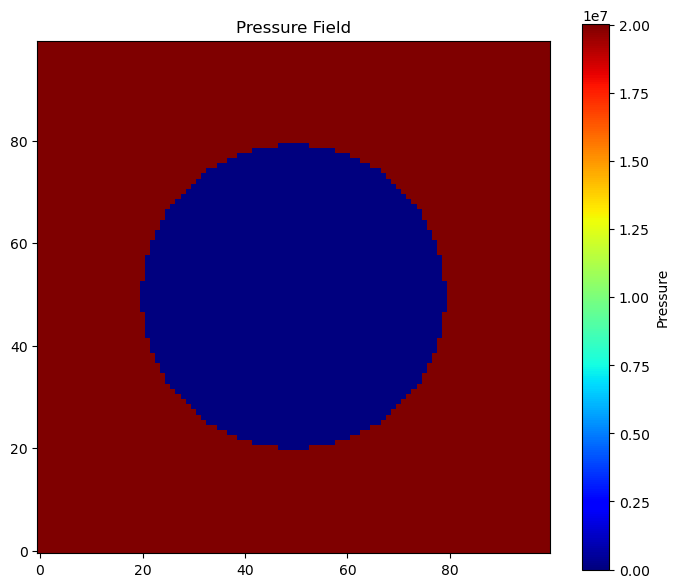

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,6))

plt.imshow(P[:,0,:],
           origin='lower',
           cmap='jet')

plt.colorbar(label="Pressure")

plt.title("Pressure Field")

plt.tight_layout()

plt.show()

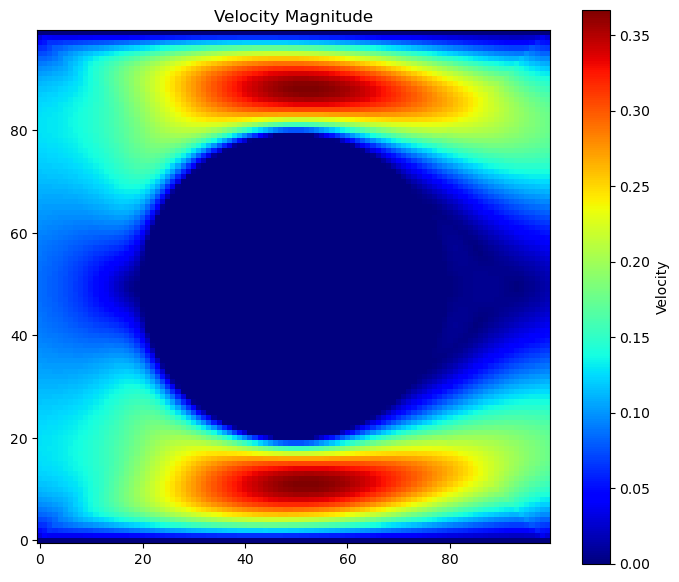

In [41]:
plt.figure(figsize=(7,6))

plt.imshow(Velocity[:,0,:],
           origin='lower',
           cmap='jet')

plt.colorbar(label="Velocity")

plt.title("Velocity Magnitude")

plt.tight_layout()

plt.show()

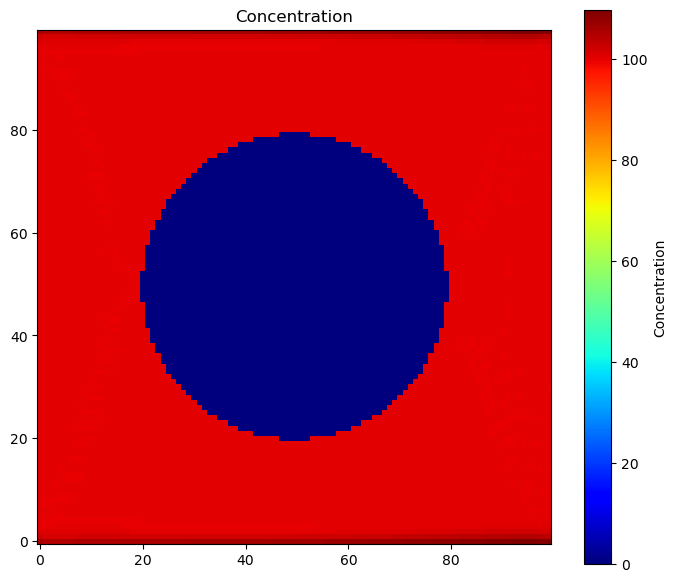

In [42]:
plt.figure(figsize=(7,6))

plt.imshow(C[:,0,:],
           origin='lower',
           cmap='jet')

plt.colorbar(label="Concentration")

plt.title("Concentration")

plt.tight_layout()

plt.show()

In [43]:
print("="*80)

print("Concentration")

print(C.shape)

print(C.dtype)

print()

print("="*80)

print("Velocity")

print(U.shape)

print(U.dtype)

print()

print("="*80)

print("Pressure")

print(P.shape)

print(P.dtype)

print()

print("="*80)

print("Pressure_rgh")

print(PRGH.shape)

print()

print("="*80)

print("Density")

print(RHO.shape)

print()

print("="*80)

print("Viscosity")

print(VISC.shape)

Concentration
(100, 1, 100)
float32

Velocity
(100, 1, 100, 3)
float32

Pressure
(100, 1, 100)
float32

Pressure_rgh
(100, 1, 100)

Density
(100, 1, 100)

Viscosity
(100, 1, 100)


In [44]:
print()

print("Velocity")

print(Velocity.min())

print(Velocity.max())

print(Velocity.mean())

print()

print("Pressure")

print(P.min())

print(P.max())

print(P.mean())

print()

print("Concentration")

print(C.min())

print(C.max())

print(C.mean())


Velocity
0.0
0.3668893
0.104294755

Pressure
0.0
20016400.0
14499820.0

Concentration
0.0
109.83687
72.647316


In [48]:
print(np.unique(RHO))
print(np.unique(VISC))

[   0.     1064.8992 1064.9075 ... 1069.7181 1069.8333 1069.8427]
[0.         0.00117878 0.00117881 ... 0.00119249 0.00119283 0.00119284]


In [49]:
Feed_Pressure = np.mean(P[:,0,0])

Outlet_Pressure = np.mean(P[:,0,-1])

Pressure_Drop = Feed_Pressure - Outlet_Pressure

In [50]:
print("Feed Pressure :",Feed_Pressure)
print("Outlet Pressure :",Outlet_Pressure)
print("Pressure Drop :",Pressure_Drop)

Feed Pressure : 20016380.0
Outlet Pressure : 20016300.0
Pressure Drop : 80.0


In [51]:
Feed_Velocity = np.mean(Velocity[:,0,0])

Outlet_Velocity = np.mean(Velocity[:,0,-1])

Mean_Velocity = np.mean(Velocity)

Max_Velocity = np.max(Velocity)

In [52]:
feed = P[:,0,0:5]
feed = feed[feed != 0]

Feed_Pressure = np.mean(feed)

outlet = P[:,0,-5:]
outlet = outlet[outlet != 0]

Outlet_Pressure = np.mean(outlet)

In [54]:
print("Feed Pressure :",Feed_Pressure)

print("Outlet Pressure :",Outlet_Pressure)

print("Pressure Drop :",Feed_Pressure - Outlet_Pressure)

print("Feed Velocity :",Feed_Velocity)

print("Outlet Velocity :",Outlet_Velocity)

print("Mean Velocity :",Mean_Velocity)

print("Max Velocity :",Max_Velocity)

Feed Pressure : 20016374.0
Outlet Pressure : 20016300.0
Pressure Drop : 74.0
Feed Velocity : 0.10089573
Outlet Velocity : 0.10357473
Mean Velocity : 0.104294755
Max Velocity : 0.3668893


In [55]:
# Research review: Whole-table normalization and summary-derived predictors require training-fold refitting and a target-leakage review before predictive evaluation. Pressure_Gradient divides by a grid count, not a verified physical channel length; Reynolds_Proxy and Peclet_Proxy are proxies with unverified units.
import pandas as pd
import numpy as np

# ============================================
# Load Existing Dataset
# ============================================

df = pd.read_excel("Summary_CFD_Dataset.xlsx")

eps = 1e-12

# ============================================
# Pressure Features
# ============================================

df["Pressure_Range"] = df["Max_Pressure"] - df["Min_Pressure"]

df["Pressure_CV"] = df["Std_Pressure"] / (df["Mean_Pressure"] + eps)

df["Pressure_Gradient"] = df["Pressure_Range"] / df["Grid_X"]

df["Normalized_Pressure"] = (
    df["Mean_Pressure"] - df["Mean_Pressure"].min()
) / (
    df["Mean_Pressure"].max() - df["Mean_Pressure"].min() + eps
)

# ============================================
# Velocity Features
# ============================================

df["Velocity_Range"] = df["Max_Velocity"] - df["Min_Velocity"]

df["Velocity_CV"] = df["Std_Velocity"] / (df["Mean_Velocity"] + eps)

df["Velocity_Uniformity"] = 1 - df["Velocity_CV"]

df["Velocity_Resultant"] = np.sqrt(
    df["Mean_Ux"]**2 +
    df["Mean_Uy"]**2 +
    df["Mean_Uz"]**2
)

# ============================================
# Concentration Features
# ============================================

df["Concentration_Range"] = (
    df["Max_Concentration"] -
    df["Min_Concentration"]
)

df["Concentration_CV"] = (
    df["Std_Concentration"] /
    (df["Mean_Concentration"] + eps)
)

df["Normalized_Concentration"] = (
    df["Mean_Concentration"] -
    df["Mean_Concentration"].min()
) / (
    df["Mean_Concentration"].max() -
    df["Mean_Concentration"].min() + eps
)

# ============================================
# Density Features
# ============================================

df["Density_CV"] = (
    df["Mean_Density"].std() /
    (df["Mean_Density"].mean() + eps)
)

df["Density_Normalized"] = (
    df["Mean_Density"] -
    df["Mean_Density"].min()
) / (
    df["Mean_Density"].max() -
    df["Mean_Density"].min() + eps
)

# ============================================
# Viscosity Features
# ============================================

df["Viscosity_CV"] = (
    df["Mean_Viscosity"].std() /
    (df["Mean_Viscosity"].mean() + eps)
)

df["Viscosity_Normalized"] = (
    df["Mean_Viscosity"] -
    df["Mean_Viscosity"].min()
) / (
    df["Mean_Viscosity"].max() -
    df["Mean_Viscosity"].min() + eps
)

# ============================================
# Hydraulic Features
# ============================================

df["Hydraulic_Resistance"] = (
    df["Pressure_Range"] /
    (df["Mean_Velocity"] + eps)
)

df["Flow_Index"] = (
    df["Mean_Velocity"] *
    df["Grid_X"] *
    df["Grid_Y"]
)

df["Pressure_Velocity_Ratio"] = (
    df["Mean_Pressure"] /
    (df["Mean_Velocity"] + eps)
)

# ============================================
# Concentration Transport
# ============================================

df["Transport_Index"] = (
    df["Mean_Velocity"] *
    df["Mean_Concentration"]
)

df["Density_Viscosity_Ratio"] = (
    df["Mean_Density"] /
    (df["Mean_Viscosity"] + eps)
)

# ============================================
# Reynolds Proxy
# ============================================

df["Reynolds_Proxy"] = (
    df["Mean_Density"] *
    df["Mean_Velocity"] *
    df["Spacer_mm"]
) / (
    df["Mean_Viscosity"] + eps
)

# ============================================
# Peclet Proxy
# ============================================

df["Peclet_Proxy"] = (
    df["Mean_Velocity"] *
    df["Spacer_mm"]
)

# ============================================
# Energy Loss Index
# ============================================

df["Energy_Loss_Index"] = (
    df["Pressure_Range"] *
    df["Mean_Velocity"]
)

# ============================================
# Membrane Performance Proxy
# ============================================

df["Membrane_Performance"] = (
    df["Mean_Velocity"] /
    (df["Pressure_Range"] + eps)
)

# ============================================
# Spacer Performance
# ============================================

df["Spacer_Performance"] = (
    df["Mean_Velocity"] *
    df["Spacer_mm"]
)

# ============================================
# Combined Performance Index
# ============================================

df["Overall_Performance_Index"] = (
    df["Velocity_Uniformity"] *
    df["Membrane_Performance"]
)

# ============================================
# Save
# ============================================

df.to_excel(
    "Summary_CFD_Dataset_FeatureEngineered.xlsx",
    index=False
)

print("Done")

print(df.shape)

print(df.head())

Done
(1268, 50)
   Configuration_Number  Spacer_mm        Resolution  Image  Grid_X  Grid_Y  \
0                     1       0.75  HR_spacer_images      1     100     100   
1                     1       0.75  HR_spacer_images      2     100     100   
2                     1       0.75  HR_spacer_images      3     100     100   
3                     1       0.75  HR_spacer_images      4     100     100   
4                     1       0.75  HR_spacer_images      5     100     100   

   Mean_Concentration  Std_Concentration  Min_Concentration  \
0           72.647316          44.821972                  0   
1           72.768738          44.908180                  0   
2           72.861549          44.975273                  0   
3           72.941391          45.033623                  0   
4           73.013184          45.086540                  0   

   Max_Concentration  ...   Flow_Index  Pressure_Velocity_Ratio  \
0         109.836868  ...  1042.947546             1.390273e+08